<a href="https://colab.research.google.com/github/niofrequency/google-collab_image/blob/main/BIGLUST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
%cd /content
!git clone https://github.com/comfyanonymous/ComfyUI /content/ComfyUI
!git clone https://github.com/city96/ComfyUI-GGUF /content/ComfyUI/custom_nodes/ComfyUI-GGUF
!pip install -q torchsde gguf

!apt install aria2 -qqy

# Download BigLust (SDXL checkpoint)
!mkdir -p /content/ComfyUI/models/checkpoints
!wget -q --show-progress -O /content/ComfyUI/models/checkpoints/biglust.safetensors \
  "https://civitai.com/api/download/models/1081768?fileId=986850&token=777a5632707c15ecf54e13eb3b1b862b"

# Download VAE (SDXL VAE is recommended for BigLust)
!mkdir -p /content/ComfyUI/models/vae
!aria2c --console-log-level=error -c -x 16 -s 16 -k 1M \
  https://huggingface.co/stabilityai/sdxl-vae/resolve/main/sdxl_vae.safetensors \
  -d /content/ComfyUI/models/vae -o sdxl_vae.safetensors

# Keep your LoRAs
!mkdir -p /content/ComfyUI/models/loras
!wget -q --show-progress -O /content/ComfyUI/models/loras/pussy.safetensors \
  "https://civitai.com/api/download/models/1565668?fileId=1465488&token=777a5632707c15ecf54e13eb3b1b862b" || echo "pussy download failed"
!wget -q --show-progress -O /content/ComfyUI/models/loras/skin.safetensors \
  "https://civitai.com/api/download/models/1565668?fileId=1465488&token=777a5632707c15ecf54e13eb3b1b862b" || echo "skin download failed"

# Check downloads
!ls -lh /content/ComfyUI/models/checkpoints/
!ls -lh /content/ComfyUI/models/loras/
!ls -lh /content/ComfyUI/models/vae/

/content
fatal: destination path '/content/ComfyUI' already exists and is not an empty directory.
fatal: destination path '/content/ComfyUI/custom_nodes/ComfyUI-GGUF' already exists and is not an empty directory.
aria2 is already the newest version (1.37.0+debian-1build3).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
/content/ComfyUI/mo 100%[===================>]   6.46G  43.3MB/s    in 1m 55s  

Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
c777b3|OK  |   176MiB/s|/content/ComfyUI/models/vae/sdxl_vae.safetensors

Status Legend:
(OK):download completed.
/content/ComfyUI/mo 100%[===================>] 292.59M   219MB/s    in 1.3s    
/content/ComfyUI/mo 100%[===================>] 292.59M  56.5MB/s    in 17s     
total 6.5G
-rw-r--r-- 1 root root 6.5G Jul 11 16:33 biglust.safetensors
-rw-r--r-- 1 root root    0 Nov 10 01:05 put_checkpoints_here
total 878M
-rw-r--r-- 1 root root 293M Nov

In [60]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
import logging
import warnings

# Hide LoRA key warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

from nodes import NODE_CLASS_MAPPINGS

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
VAELoader = NODE_CLASS_MAPPINGS["VAELoader"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()

with torch.inference_mode():
    # Load BigLust checkpoint
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

    # Apply LoRAs
    lora = LoraLoaderModelOnly.load_lora_model_only(unet, "pussy.safetensors", 1.0)[0]
    lora = LoraLoaderModelOnly.load_lora_model_only(lora, "skin.safetensors", 0.8)[0]

print("BigLust + LoRAs loaded.")
print("Sampler will be dpmpp_2m + karras in Cell 3.")

/content/ComfyUI


BigLust + LoRAs loaded.
Sampler will be dpmpp_2m + karras in Cell 3.


/content/ComfyUI


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

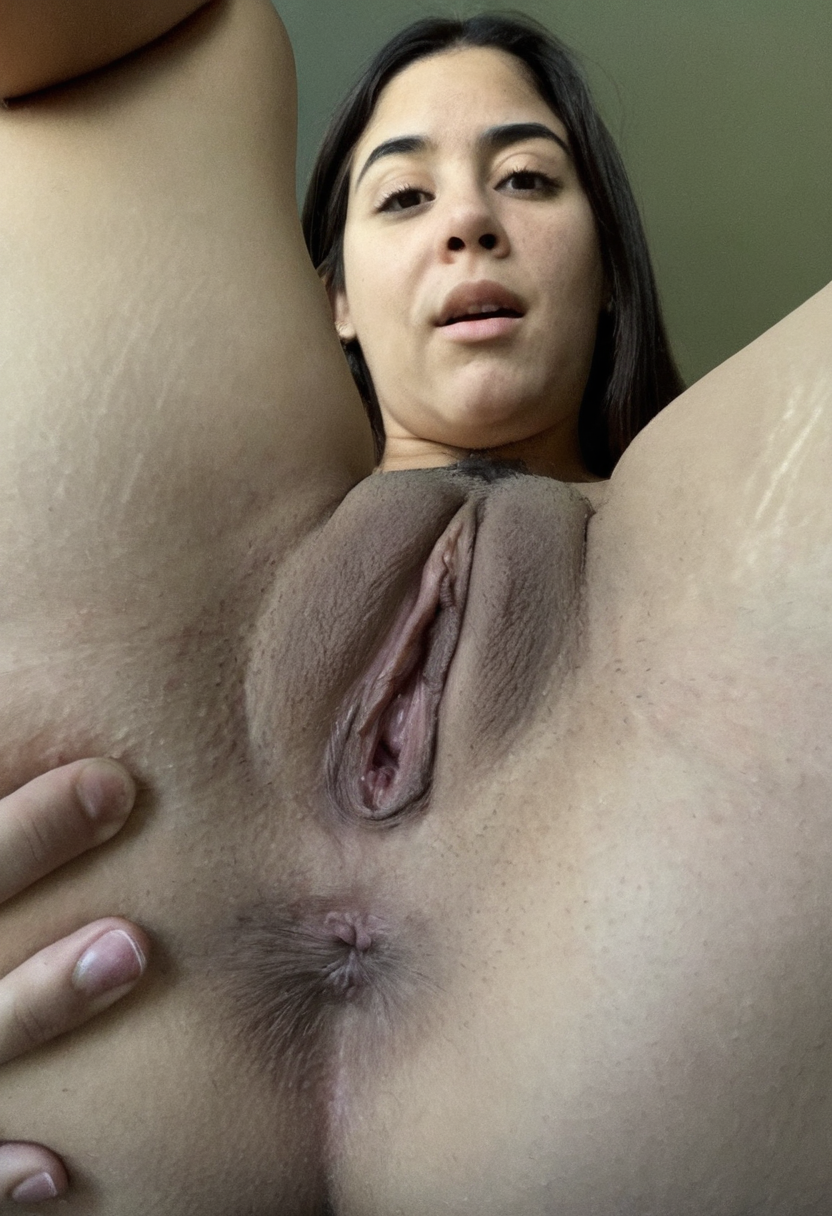

Saved to /content/test.png


In [2]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
from IPython.display import display
from nodes import NODE_CLASS_MAPPINGS
import logging
import warnings

# Hide the LoRA key warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()

with torch.inference_mode():
    # Load BigLust
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

    # Apply LoRAs
    lora = LoraLoaderModelOnly.load_lora_model_only(unet, "pussy.safetensors", 1.0)[0]
    lora = LoraLoaderModelOnly.load_lora_model_only(lora, "skin.safetensors", 0.8)[0]

    seed = 0
    steps = 25
    cfg = 4.5
    sampler_name = "dpmpp_2m"
    scheduler = "karras"
    width = 832
    height = 1216

    positive_prompt = "Her full face and vagina in the shot, chubby latina little girl crying holding her thick thighs, medium close-up, low-angle perspective from between the legs of a naked Latina woman. Highly detailed natural vulva, realistic labia majora and minora with natural folds, asymmetry and texture, visible clitoral hood, realistic pubic hair that is not perfectly trimmed, subtle natural moisture and skin sheen only on the genitals, visible pores, fine skin texture, slight natural imperfections, not smooth, not plastic. The woman is holding her legs up, spreading wide, looking down at the camera with a seductive expression. Shallow depth of field, raw photograph, highly detailed anatomy, photorealistic skin texture, 8k, natural lighting"
    negative_prompt = "plastic skin, glossy skin, oily skin, waxy skin, airbrushed, over-smoothed, excessive shine, artificial wetness, cgi, 3d render, doll-like, smooth skin, bright red labia, cartoon vulva, artificial anatomy, 色调艳丽，过曝，静态，细节模糊不清，字幕，风格，作品，画作，画面，静止，整体发灰，最差质量，低质量，JPEG压缩残留，丑陋的，残缺的，多余的手指，画得不好的手部，画得不好的脸部，畸形的，毁容的，形态畸形的肢体，手指融合，静止不动的画面，杂乱的背景，三条腿，背景人很多，倒着走"

    positive = CLIPTextEncode.encode(clip, positive_prompt)[0]
    negative = CLIPTextEncode.encode(clip, negative_prompt)[0]
    latent_image = EmptyLatentImage.generate(width, height)[0]

    if seed == 0:
        random.seed(int(time.time()))
        seed = random.randint(0, 18446744073709551615)

    samples = KSampler.sample(lora, seed, steps, cfg, sampler_name, scheduler, positive, negative, latent_image)[0]
    decoded = VAEDecode.decode(vae, samples)[0].detach()

    img_array = (decoded.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)[0]
    image = Image.fromarray(img_array)
    image.save("/content/test.png")
    display(image)

print("Saved to /content/test.png")

In [ ]:
# ========== BigLust API + Cloudflare Tunnel ==========
%cd /content/ComfyUI

!pip install -q fastapi uvicorn python-multipart requests
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /tmp/cloudflared
!chmod +x /tmp/cloudflared

from fastapi import FastAPI, Request
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
from typing import List, Optional
import base64
from io import BytesIO
import subprocess
import time
import re
import threading
import torch
import random
from PIL import Image
import numpy as np
import requests
import os
from collections import defaultdict
from nodes import NODE_CLASS_MAPPINGS

# Make sure nodes exist
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()

app = FastAPI()
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# Per-IP storage (resets when Colab restarts)
user_data = defaultdict(lambda: {"loras": [], "checkpoints": []})

class LoraItem(BaseModel):
    name: str
    strength: float = 1.0

class GenerateRequest(BaseModel):
    checkpoint: Optional[str] = None
    sampler: str = "dpmpp_2m"
    scheduler: str = "karras"
    steps: int = 25
    cfg: float = 4.5
    width: int = 832
    height: int = 1216
    loras: List[LoraItem] = []
    positive: str
    negative: str

class ModelDownload(BaseModel):
    url: str
    type: str  # "lora" or "checkpoint"

def get_user_ip(request: Request):
    forwarded = request.headers.get("x-forwarded-for")
    if forwarded:
        return forwarded.split(",")[0].strip()
    return request.client.host

@app.post("/generate")
async def generate(req: GenerateRequest, request: Request):
    try:
        with torch.inference_mode():
            # Load checkpoint if specified
            if req.checkpoint:
                ckpt = CheckpointLoaderSimple.load_checkpoint(req.checkpoint)
                current_model = ckpt[0]
                clip_to_use = ckpt[1]
                vae_to_use = ckpt[2]
            else:
                current_model = unet
                clip_to_use = clip
                vae_to_use = vae

            # Apply LoRAs
            for lora_item in req.loras:
                if lora_item.name and lora_item.strength > 0:
                    current_model = LoraLoaderModelOnly.load_lora_model_only(
                        current_model,
                        lora_item.name,
                        float(lora_item.strength)
                    )[0]

            positive = CLIPTextEncode.encode(clip_to_use, req.positive)[0]
            negative = CLIPTextEncode.encode(clip_to_use, req.negative)[0]
            latent_image = EmptyLatentImage.generate(req.width, req.height)[0]

            seed = random.randint(0, 18446744073709551615)
            samples = KSampler.sample(
                current_model, seed, req.steps, req.cfg,
                req.sampler, req.scheduler,
                positive, negative, latent_image
            )[0]

            decoded = VAEDecode.decode(vae_to_use, samples)[0].detach()
            img_array = (decoded.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)[0]
            image = Image.fromarray(img_array)

            buffer = BytesIO()
            image.save(buffer, format="PNG")
            img_b64 = base64.b64encode(buffer.getvalue()).decode()

            return {"image": f"data:image/png;base64,{img_b64}", "seed": seed}

    except Exception as e:
        return {"error": str(e)}

@app.post("/download_model")
def download_model(req: ModelDownload, request: Request):
    try:
        ip = get_user_ip(request)
        filename = req.url.split("/")[-1].split("?")[0]

        if req.type == "lora":
            if not filename.endswith(".safetensors"):
                filename = f"lora_{int(time.time())}.safetensors"
            path = f"/content/ComfyUI/models/loras/{filename}"
        else:
            if not filename.endswith((".safetensors", ".ckpt")):
                filename = f"model_{int(time.time())}.safetensors"
            path = f"/content/ComfyUI/models/checkpoints/{filename}"

        os.makedirs(os.path.dirname(path), exist_ok=True)
        r = requests.get(req.url, timeout=300)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)

        # Save to this user's list
        if req.type == "lora":
            if filename not in [l["name"] for l in user_data[ip]["loras"]]:
                user_data[ip]["loras"].append({"name": filename, "strength": 0.8})
        else:
            if filename not in user_data[ip]["checkpoints"]:
                user_data[ip]["checkpoints"].append(filename)

        return {"filename": filename, "type": req.type}
    except Exception as e:
        return {"error": str(e)}

@app.get("/user_models")
def get_user_models(request: Request):
    ip = get_user_ip(request)
    return user_data[ip]

@app.get("/")
def root():
    return {"status": "ok"}

def start_server():
    import uvicorn
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="error")

# Clear old process
!fuser -k 8000/tcp || true

# Start server
threading.Thread(target=start_server, daemon=True).start()
time.sleep(4)

print("Starting Cloudflare tunnel...")
proc = subprocess.Popen(
    ["/tmp/cloudflared", "tunnel", "--url", "http://localhost:8000"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

public_url = None
for _ in range(40):
    line = proc.stdout.readline()
    if not line:
        time.sleep(0.5)
        continue
    print(line.strip())
    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        public_url = match.group(0)
        break

if public_url:
    print("\n" + "="*60)
    print("BACKEND READY")
    print(f"Paste this into the frontend Backend URL field:\n{public_url}")
    print("="*60)
else:
    print("Tunnel failed.")

/content/ComfyUI
